# Expectation-maximization algorithm

## Introduction

In this exercise you will segment three tissue classes in an MR image based on a generative model which you will fit to the image data. You will perform the Expectation-Maximization algorithm to fit the model parameters.
The MR data for this exercise consists of a 2-dimensional slice of a brain scan in the axial
orientation. The file _segmentData.mat_ contains the original slice as well as a mask that excludes
non-brain tissues such as eyeballs, fat, skin, etc. The file _correctedData.mat_ contains the same
image, but after it has been corrected for the MR bias field artifact using the method described in
section 3.5. It is this image you will be modeling.

### Instructions for your report
Your report should be structured as follows:
* **Introduction**: a short summary of what your report is about, perhaps with a recap of some of the equations you'll be using in your solution.
* **Task 1, ..., 5**: for each specific task listed below, your code (in code cells), your results (as figures) as well as explanations of what is computed and what is shown in the figures (in Markdown cells). 
* **Conclusion**: a short summary of your findings.

This introduction should **not** be part of your report.

### Input data and code hints
Import Python libraries:

In [1]:
import numpy as np
import scipy
from scipy.io import loadmat
from scipy import signal
import warnings
warnings.filterwarnings("ignore")
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import norm
import matplotlib.mlab as mlab
%matplotlib inline

## Task 1: Image data
Display the image provided in "correctedData.mat" and plot its histogram.

> ***Hints:***
> - .mat data can be loaded in python as follows
>   
>       mat = loadmat("correctedData.mat")
> 
>       data = mat["correctedData"]
>
> - Use 100 bins for your histogram
> - The mask sets all background pixels to zero. Disregard the background pixels by clipping 0.

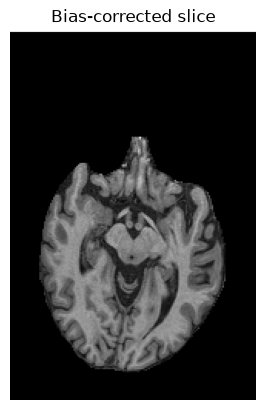

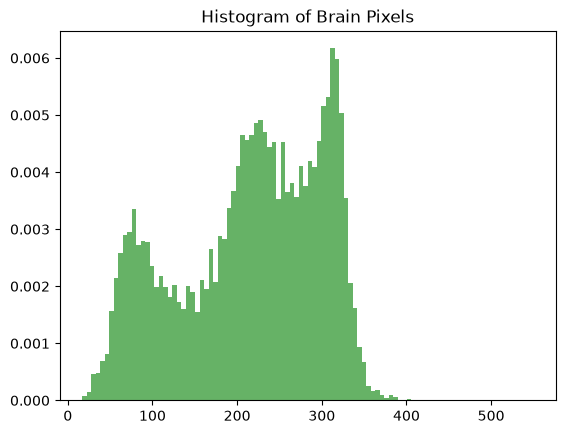

In [2]:
# Load data
mat = loadmat("correctedData.mat")
data = mat["correctedData"]

# Disregard background pixels by clipping 0
brain_pixels = data[data > 0]

plt.imshow(data, cmap='gray'); plt.title("Bias-corrected slice"); plt.axis('off'); plt.show()

# Plot histogram
counts, bins, patches = plt.hist(brain_pixels, bins=100, density=True, alpha=0.6, color='g')
plt.title("Histogram of Brain Pixels")
plt.show()

## Task 2: Initialize Gaussian-Mixture Model
Compute the minimum and maximum intensity in the image (non-zero pixels), and divide the
intensity range up into three equally wide intervals. Initialize the parameters of a 3-component
Gaussian mixture model by setting the means of the Gaussians to the centers of the intensity
intervals, the variances to the square of the width of the intervals, and the prior weights to $\frac{1}{3}$ each.

> ***Hint:***
> - In your intensity range, disregard the background pixels by clipping 0

In [3]:
# Compute min, max, and interval width
min_val = np.min(brain_pixels)
max_val = np.max(brain_pixels)
interval_width = (max_val - min_val) / 3

# Initialize means to the centers of the 3 intervals
mu = [min_val + interval_width * 0.5, 
      min_val + interval_width * 1.5, 
      min_val + interval_width * 2.5]

# Initialize variances to the square of the interval width
variance = [interval_width**2] * 3
sigma = np.sqrt(variance)

# Initialize prior weights to 1/3 each
pi = [1/3, 1/3, 1/3]

## Task 3: Display inital Gaussian distributions
Overlay the resulting Gaussian mixture model on the histogram by plotting each
Gaussian weighted by its $\pi_k$, as well as the total weighted sum of all three Gaussian distributions
(as in fig. 3.1(b) in the course notes).

> ***Hint:***
> - A gaussian distribution with the parameters $\mu$, $\sigma^2$, scaled by the weight $w$ and evaluated at positions $x$ can be obtained by the function
>        
>        w * scipy.stats.norm.pdf( x, mu, sigma).
>
> - you can use the bin edges of your histogram as $x$.

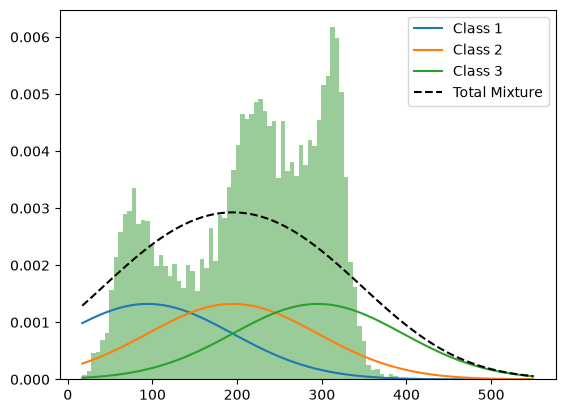

In [14]:
x = bins # use bin edges for x-axis
total_pdf = np.zeros_like(x)

plt.hist(brain_pixels, bins=100, density=True, alpha=0.4, color='g')

for k in range(3):
    # Calculate weighted Gaussian
    weighted_pdf = pi[k] * scipy.stats.norm.pdf(x, mu[k], sigma[k])
    total_pdf += weighted_pdf
    plt.plot(x, weighted_pdf, label=f'Class {k+1}')

# Plot total weighted sum
plt.plot(x, total_pdf, 'k--', label='Total Mixture')
plt.legend()
plt.show()

In [11]:
print("min:", brain_pixels.min(), " max:", brain_pixels.max())
print("99th percentile:", np.percentile(brain_pixels, 99))
print("pixels above 400:", np.sum(brain_pixels > 400), "of", brain_pixels.size)

min: 17.078205010324904  max: 549.6669350144115
99th percentile: 345.5969937399978
pixels above 400: 5 of 13272


The intensity range of the brain pixels is [17.1, 549.7], giving three intervals of width 177.5 and initial means 105.8, 283.4 and 460.9, each with σ = 177.5 and π = 1/3. However, the maximum is set by a handful of outliers: only 5 of the 13 272 pixels (0.04%) exceed 400, and 99% lie below 345.6. These pixels are too few to be visible in the histogram, but they stretch the intensity range far beyond where the data actually lies. As a result, the third Gaussian is centred in an almost empty region of the histogram, and all three components are much wider than the tissue peaks, so the initial mixture fits the histogram poorly.

To avoid this, we repeat the initialisation using the 1st–99th percentile range [43.9, 345.6] instead of the minimum and maximum, so that the three intervals cover the region where the intensities are concentrated.

percentile range: [43.9, 345.6]   interval width: 100.6
initial means: [ 94.2 194.8 295.3]


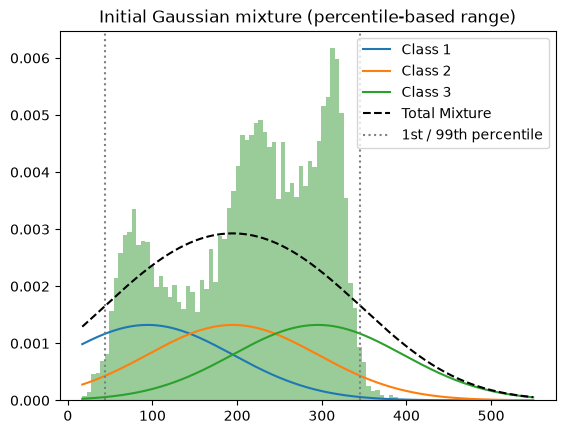

In [16]:
# Re-initialise using the 1st-99th percentile range instead of min/max
lo, hi = np.percentile(brain_pixels, [1, 99])
interval_width = (hi - lo) / 3

# Means at the centres of the three intervals
mu = np.array([lo + interval_width * 0.5,
               lo + interval_width * 1.5,
               lo + interval_width * 2.5])

# Variances = squared interval width, priors = 1/3 (same rules as Task 2)
variance = np.full(3, interval_width**2)
sigma = np.sqrt(variance)
pi = np.full(3, 1/3)

print(f"percentile range: [{lo:.1f}, {hi:.1f}]   interval width: {interval_width:.1f}")
print("initial means:", np.round(mu, 1))

# Plot the new initial mixture on the histogram (same style as Task 3)
x = np.linspace(brain_pixels.min(), brain_pixels.max(), 500)
total_pdf = np.zeros_like(x)

plt.hist(brain_pixels, bins=100, density=True, alpha=0.4, color='g')
for k in range(3):
    weighted_pdf = pi[k] * norm.pdf(x, mu[k], sigma[k])
    total_pdf += weighted_pdf
    plt.plot(x, weighted_pdf, label=f'Class {k+1}')
plt.plot(x, total_pdf, 'k--', label='Total Mixture')
plt.axvline(lo, color='gray', ls=':', label='1st / 99th percentile')
plt.axvline(hi, color='gray', ls=':')
plt.title('Initial Gaussian mixture (percentile-based range)')
plt.legend()
plt.show()

## Task 4: Compute weights
Compute the values of ${w}_{n,k}$ defined by:

$$ \mathcal{w}_{n,k} = \frac{\mathcal{N}(d_n \vert \tilde{\mu}_k, \tilde{\sigma}^2_k) \tilde{\pi}_k}{\sum^K_{k'=1} \mathcal{N}(d_n \vert \tilde{\mu}_k', \tilde{\sigma}^2_{k'}) \tilde{\pi}_k'}. $$

Visualize the values of each ${w}_{n,k}$ in a figure. You should have three plots which each display only the pixels that belong to the respective class, according to the weights.

> ***Hint:***
> - The segmentation of a pixel is determined by assigning the class of the highest probability. 
> - In your visualization, disregard the background pixels by clipping 0

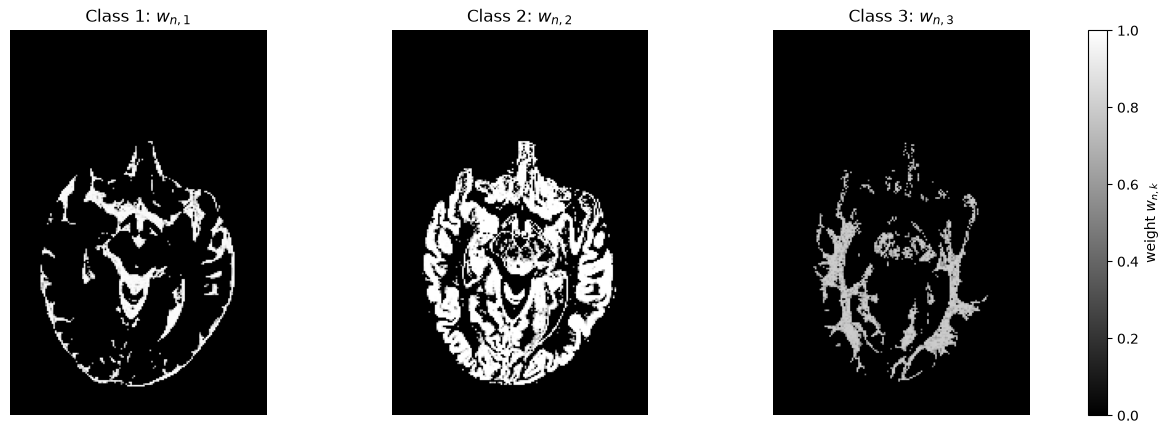

In [22]:
# Calculate probabilities for each class
w = np.zeros((len(brain_pixels), 3))
for k in range(3):
    w[:, k] = pi[k] * scipy.stats.norm.pdf(brain_pixels, mu[k], sigma[k])

# Normalize weights so they sum to 1 for each pixel
w_sum = np.sum(w, axis=1)
w = w / w_sum[:, np.newaxis]

# Assign class based on highest probability
segmentation = np.argmax(w, axis=1)

# Show the weight values w_{n,k}, only on the pixels assigned to class k
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for k in range(3):
    img = np.zeros_like(data, dtype=float)                      # background stays 0
    img[data > 0] = np.where(segmentation == k, w[:, k], 0)     # weight if assigned to k, else 0
    im = axes[k].imshow(img, cmap='gray', vmin=0, vmax=1)
    axes[k].set_title(f'Class {k+1}: $w_{{n,{k+1}}}$')
    axes[k].axis('off')
fig.colorbar(im, ax=axes, fraction=0.02, label='weight $w_{n,k}$')
plt.show()

## Task 5: Estimate Maximum Likelihood parameters
Estimate the maximum likelihood parameters by iterating between updating the model parameter
estimate according to 

$$ \tilde{\mu_k} \leftarrow \frac{\sum^N_{n=1} w_{n,k} d_n}{\sum^N_{n=1} w_{n,k}}  $$

$$ \tilde{\sigma}^2_k \leftarrow \frac{\sum^N_{n=1} w_{n,k} (d_n - \tilde{\mu_k})^2}{\sum^N_{n=1} w_{n,k}}  $$

$$ \tilde{\pi_k} \leftarrow \frac{\sum^N_{n=1} w_{n,k}}{N}  $$

and by recomputing ${w}_{n,k}$ according to eq. 3.33 (see Task 4).

Make sure to perform enough iterations (e.g., 100) for the algorithm to converge. As the iterations progress, plot
the evolution of the log likelihood function, and update each time the display of ${w}_{n,k}$ as well as
the Gaussian mixture model plot overlaid on the histogram. Include the evolution of the log
likelihood function and the plot of the final ${w}_{n,k}$ and the final mixture model in your report.

> ***Hint:***
> - The log likelihood can be simply computed by
>       $\log ( \sum_k w_k x_k )$

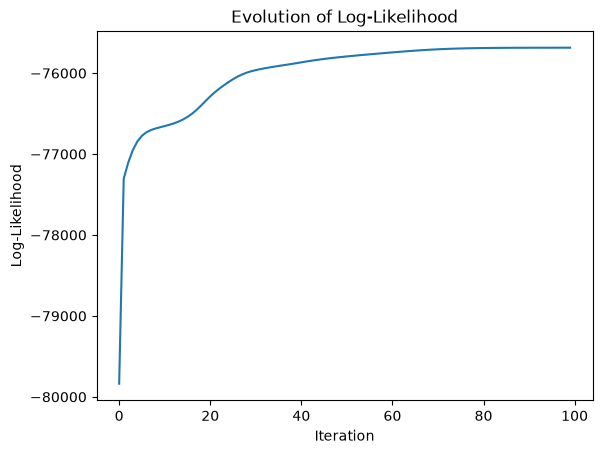

In [18]:
iterations = 100
log_likelihoods = []
N = len(brain_pixels)

for i in range(iterations):
    # --- E-step ---
    pdf_vals = np.zeros((N, 3))
    for k in range(3):
        pdf_vals[:, k] = pi[k] * scipy.stats.norm.pdf(brain_pixels, mu[k], sigma[k])
    
    w_sum = np.sum(pdf_vals, axis=1)
    
    # Calculate log likelihood: log(sum(w_k * N(x | mu_k, sigma_k)))
    log_likelihood = np.sum(np.log(w_sum))
    log_likelihoods.append(log_likelihood)
    
    w = pdf_vals / w_sum[:, np.newaxis]
    
    # --- M-step ---
    for k in range(3):
        N_k = np.sum(w[:, k])
        # Update mean
        mu[k] = np.sum(w[:, k] * brain_pixels) / N_k
        # Update variance
        sigma[k] = np.sqrt(np.sum(w[:, k] * (brain_pixels - mu[k])**2) / N_k)
        # Update prior weight
        pi[k] = N_k / N

# Plot Log-Likelihood evolution
plt.plot(log_likelihoods)
plt.title("Evolution of Log-Likelihood")
plt.xlabel("Iteration")
plt.ylabel("Log-Likelihood")
plt.show()

## Task 6: Vary only one model parameter
Keeping all other parameters fixed to their estimated values, vary only $\mu_2$ (the mean of the middle
Gaussian distribution) between the estimated values of $\mu_1$ and $\mu_3$ in about 100 steps, and plot for
each step the log likelihood function.

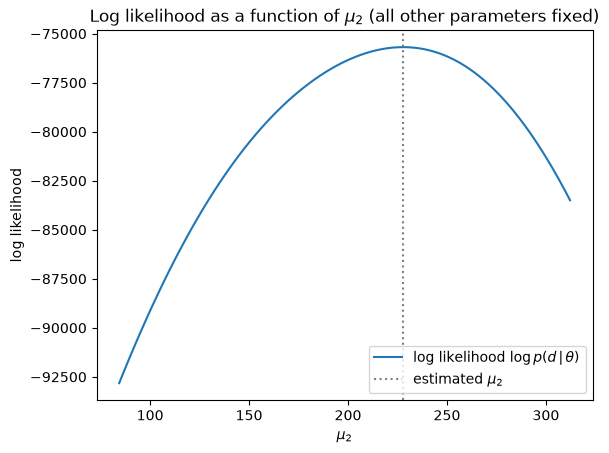

estimated mu_2: 227.84529058244584
mu_2 at the peak of the curve: 227.0490313212477


In [19]:
mu_hat    = np.array(mu, dtype=float)      
sigma_hat = np.array(sigma, dtype=float)   
pi_hat    = np.array(pi, dtype=float)
d = brain_pixels.astype(float)

def log_lik(mu_, sigma_, pi_):
    """log p(d | theta) = sum over voxels of log( sum over classes of pi_k * N(d_n | mu_k, sigma_k^2) )"""
    p = sum(pi_[k] * norm.pdf(d, mu_[k], sigma_[k]) for k in range(3))
    return np.sum(np.log(p))

mu2_grid = np.linspace(mu_hat[0], mu_hat[2], 100)
LL = []
for m in mu2_grid:
    mu_try = mu_hat.copy()
    mu_try[1] = m                      # change mu_2 only
    LL.append(log_lik(mu_try, sigma_hat, pi_hat))
LL = np.array(LL)

plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.axvline(mu_hat[1], color='gray', ls=':', label=r'estimated $\mu_2$')
plt.xlabel(r'$\mu_2$')
plt.ylabel('log likelihood')
plt.title(r'Log likelihood as a function of $\mu_2$ (all other parameters fixed)')
plt.legend()
plt.show()

print("estimated mu_2:", mu_hat[1])
print("mu_2 at the peak of the curve:", mu2_grid[np.argmax(LL)])

## Task 7: Locate Lower bound
On the same figure, also plot the lower bound corresponding to the parameter vector in which all
parameters are set to their estimated values, except $\mu_2$ which is set to the estimated value of $\mu_1$.

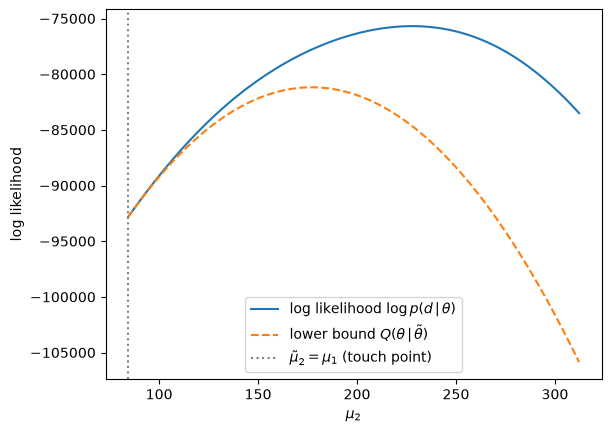

touches at mu_2 = mu_1: True -92820.82354048936 -92820.82354048955
below everywhere: True


In [20]:
import scipy.special

def weights(mu_, sigma_, pi_):
    """E-step: w_{n,k} = pi_k N(d_n | mu_k, sigma_k^2) / sum_k' (...)"""
    p = np.stack([pi_[k] * norm.pdf(d, mu_[k], sigma_[k]) for k in range(3)], axis=1)
    return p / p.sum(axis=1, keepdims=True)

def lower_bound(mu_, sigma_, pi_, w):
    """Q(theta | theta_tilde) from Task 8, with no bias field (all c_m = 0)."""
    var = sigma_**2
    Nk = w.sum(axis=0)                                   # soft counts per class
    Q = -0.5 * sum((w[:, k] * (d - mu_[k])**2).sum() / var[k]
                   + Nk[k] * np.log(var[k]) for k in range(3))
    Q += np.sum(Nk * np.log(pi_))
    Q -= scipy.special.xlogy(w, w).sum()                 # sum of w log w (0·log 0 = 0)
    Q -= len(d) / 2 * np.log(2 * np.pi)
    return Q

# 1. theta_tilde: estimates, but mu_2 set to the estimated mu_1
mu_tilde = mu_hat.copy()
mu_tilde[1] = mu_hat[0]

# 2. E-step at theta_tilde -> frozen weights
w_tilde = weights(mu_tilde, sigma_hat, pi_hat)

# 3. Evaluate the bound along the same mu_2 grid (only mu_2 changes)
Q = []
for m in mu2_grid:
    mu_try = mu_hat.copy()
    mu_try[1] = m
    Q.append(lower_bound(mu_try, sigma_hat, pi_hat, w_tilde))
Q = np.array(Q)

# 4. Plot both curves
plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.plot(mu2_grid, Q, '--', label=r'lower bound $Q(\theta\,|\,\tilde\theta)$')
plt.axvline(mu_hat[0], color='gray', ls=':', label=r'$\tilde\mu_2 = \mu_1$ (touch point)')
plt.xlabel(r'$\mu_2$')
plt.ylabel('log likelihood')
plt.legend()
plt.show()

# Sanity checks
print("touches at mu_2 = mu_1:", np.isclose(LL[0], Q[0]), LL[0], Q[0])
print("below everywhere:", np.all(Q <= LL + 1e-6))

## Task 8: Maximize lower bound
Compute the value for $\mu_2$ that maximizes this lower bound (first line of eq. 3.35), indicate its location
on the figure, and comment on the result.

Formulate the lower bound as 

$$ Q(\theta \vert \tilde{\theta}) = -\frac{1}{2} \sum^K_{k=1} [\frac{1}{\sigma^2_k} \sum^N_{n=1} w_{n,k} (d_n - \mu_k - \sum^M_{m-1} c_m \phi_{n,m})^2 + (\sum^N_{n-1} w_{n,k}) \log \sigma^2_k] $$

$$ + \sum^K_{k=1} [(\sum^N_{n=1} w_{n,k}) \log \pi_k] $$

$$ - \sum^N_{n=1} \sum^K_{k=1} w_{n,k} \log w_{n,k} - \frac{N}{2} \log (2\pi) $$


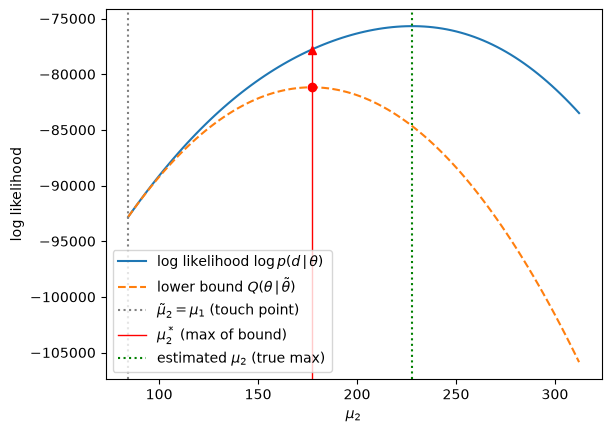

start  mu_2 = mu_1  = 84.35   log lik = -92820.82
new    mu_2*        = 177.12   log lik = -77786.37   bound = -81178.43
target estimated mu_2 = 227.85  log lik = -75686.21
bound max matches numerical argmax of Q: 176.41235676289102
went uphill: True


In [21]:
# Maximum of the lower bound: weighted mean with the frozen weights (eq. 3.35, c_m = 0)
mu2_star = np.sum(w_tilde[:, 1] * d) / np.sum(w_tilde[:, 1])

# Values of both curves at the start (mu_2 = mu_1) and at mu2_star
mu_star = mu_hat.copy(); mu_star[1] = mu2_star
LL_start = LL[0]                                     # real curve at mu_2 = mu_1
LL_star  = log_lik(mu_star, sigma_hat, pi_hat)       # real curve at mu2_star
Q_star   = lower_bound(mu_star, sigma_hat, pi_hat, w_tilde)

# Same figure as Task 7, plus the new point
plt.plot(mu2_grid, LL, label=r'log likelihood $\log p(d\,|\,\theta)$')
plt.plot(mu2_grid, Q, '--', label=r'lower bound $Q(\theta\,|\,\tilde\theta)$')
plt.axvline(mu_hat[0], color='gray', ls=':', label=r'$\tilde\mu_2 = \mu_1$ (touch point)')
plt.axvline(mu2_star, color='red', ls='-', lw=1, label=r'$\mu_2^*$ (max of bound)')
plt.plot(mu2_star, Q_star, 'ro')                     # top of the bound
plt.plot(mu2_star, LL_star, 'r^')                    # real curve at that mu_2
plt.axvline(mu_hat[1], color='green', ls=':', label=r'estimated $\mu_2$ (true max)')
plt.xlabel(r'$\mu_2$'); plt.ylabel('log likelihood'); plt.legend(); plt.show()

print(f"start  mu_2 = mu_1  = {mu_hat[0]:.2f}   log lik = {LL_start:.2f}")
print(f"new    mu_2*        = {mu2_star:.2f}   log lik = {LL_star:.2f}   bound = {Q_star:.2f}")
print(f"target estimated mu_2 = {mu_hat[1]:.2f}  log lik = {LL.max():.2f}")
print("bound max matches numerical argmax of Q:", mu2_grid[np.argmax(Q)])
print("went uphill:", LL_star > LL_start)